<a href="https://colab.research.google.com/github/carolinaaraujo-cap/C-lculo-Num-rico/blob/main/Atividade_3_C%C3%A1lculo_Num%C3%A9rico.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
import math
import pandas as pd

**Nomeando** **funções** **e parâmetros**

In [21]:

# ==========================================================
# PARÂMETROS
# ==========================================================

TOL = 1e-6
MAX_ITER = 100


# ==========================================================
# FUNÇÕES
# ==========================================================

def f1(x):
    return x**2 - 2


def df1(x):
    return 2*x


def f2(x):
    return x**3 - x - 2


def df2(x):
    return 3*x**2 - 1


def f3(x):
    return np.exp(-x) - x


def df3(x):
    return -np.exp(-x) - 1


def f4(x):
    return x**3 - 2*x + 2


def df4(x):
    return 3*x**2 - 2


Dados sugeridos das funções

In [22]:
# ==========================================================
# DADOS DAS FUNÇÕES
# ==========================================================

funcoes = {

    "f1(x) = x² - 2": {
        "f": f1,
        "df": df1,
        "intervalo": (1, 2),
        "x0": 1.5,
        "secante": (1, 2)
    },

    "f2(x) = x³ - x - 2": {
        "f": f2,
        "df": df2,
        "intervalo": (1, 2),
        "x0": 1.5,
        "secante": (1, 2)
    },

    "f3(x) = e⁻ˣ - x": {
        "f": f3,
        "df": df3,
        "intervalo": (0, 1),
        "x0": 0.5,
        "secante": (0, 1)
    },

    "f4(x) = x³ - 2x + 2": {
        "f": f4,
        "df": df4,
        "intervalo": (-2, -1),
        "x0": -2,
        "secante": (-2, -1)
    }
}

Método da Bisseção

In [23]:
# ==========================================================
# BISSEÇÃO
# ==========================================================

def bissecao(f, a, b, tol=TOL, max_iter=MAX_ITER):

    aproximacoes = []

    fa = f(a)
    fb = f(b)

    # Verifica se existe mudança de sinal
    if fa * fb > 0:

        return {
            "raiz": None,
            "iteracoes": 0,
            "aproximacoes": [],
            "convergiu": False,
            "mensagem": "Não existe mudança de sinal no intervalo."
        }


    for k in range(1, max_iter + 1):

        c = (a + b) / 2

        aproximacoes.append(c)

        fc = f(c)


        # Critério de parada
        if (
            abs(fc) < tol
            or abs(b - a) / 2 < tol
        ):

            return {
                "raiz": c,
                "iteracoes": k,
                "aproximacoes": aproximacoes,
                "convergiu": True,
                "mensagem": "Convergência alcançada."
            }


        # Escolhe o novo intervalo
        if fa * fc < 0:

            b = c
            fb = fc

        else:

            a = c
            fa = fc


    return {
        "raiz": c,
        "iteracoes": max_iter,
        "aproximacoes": aproximacoes,
        "convergiu": False,
        "mensagem": "Número máximo de iterações atingido."
    }

Método de Newton

In [24]:
# ==========================================================
# NEWTON
# ==========================================================

def newton(f, df, x0, tol=TOL, max_iter=MAX_ITER):

    aproximacoes = [x0]


    for k in range(1, max_iter + 1):

        derivada = df(x0)


        # Verifica derivada próxima de zero
        if abs(derivada) < 1e-14:

            return {
                "raiz": x0,
                "iteracoes": k - 1,
                "aproximacoes": aproximacoes,
                "convergiu": False,
                "mensagem": "Derivada próxima de zero."
            }


        # Fórmula de Newton
        x1 = (
            x0
            - f(x0) / derivada
        )


        aproximacoes.append(x1)


        # Critério de parada
        if (
            abs(x1 - x0) < tol
            and abs(f(x1)) < tol
        ):

            return {
                "raiz": x1,
                "iteracoes": k,
                "aproximacoes": aproximacoes,
                "convergiu": True,
                "mensagem": "Convergência alcançada."
            }


        x0 = x1


    return {
        "raiz": x0,
        "iteracoes": max_iter,
        "aproximacoes": aproximacoes,
        "convergiu": False,
        "mensagem": "Número máximo de iterações atingido."
    }

Método da secante

In [25]:
# ==========================================================
# SECANTE
# ==========================================================

def secante(f, x0, x1, tol=TOL, max_iter=MAX_ITER):

    aproximacoes = [
        x0,
        x1
    ]


    for k in range(1, max_iter + 1):

        f0 = f(x0)
        f1_val = f(x1)

        denominador = f1_val - f0


        # Verifica denominador próximo de zero
        if abs(denominador) < 1e-14:

            return {
                "raiz": x1,
                "iteracoes": k - 1,
                "aproximacoes": aproximacoes,
                "convergiu": False,
                "mensagem": "Denominador próximo de zero."
            }


        # Fórmula da secante
        x2 = (
            x1
            - f1_val
            * (x1 - x0)
            / denominador
        )


        aproximacoes.append(x2)


        # Critério de parada
        if (
            abs(x2 - x1) < tol
            and abs(f(x2)) < tol
        ):

            return {
                "raiz": x2,
                "iteracoes": k,
                "aproximacoes": aproximacoes,
                "convergiu": True,
                "mensagem": "Convergência alcançada."
            }


        x0 = x1
        x1 = x2


    return {
        "raiz": x1,
        "iteracoes": max_iter,
        "aproximacoes": aproximacoes,
        "convergiu": False,
        "mensagem": "Número máximo de iterações atingido."
    }

Execução dos métodos nas funções

In [26]:
# ==========================================================
# EXECUÇÃO
# ==========================================================

resultados = {}


for nome, dados in funcoes.items():

    f = dados["f"]
    df = dados["df"]

    a, b = dados["intervalo"]

    x0 = dados["x0"]

    s0, s1 = dados["secante"]


    # Bisseção
    resultados[(nome, "Bisseção")] = bissecao(
        f,
        a,
        b
    )


    # Newton
    resultados[(nome, "Newton")] = newton(
        f,
        df,
        x0
    )


    # Secante
    resultados[(nome, "Secante")] = secante(
        f,
        s0,
        s1
    )

Tabela

In [38]:
# ==========================================================
# TABELA DE RESULTADOS
# ==========================================================

tabela = []


for (nome, metodo), resultado in resultados.items():

    raiz = resultado["raiz"]


    if raiz is not None:

        residuo = abs(
            funcoes[nome]["f"](raiz)
        )

    else:

        residuo = np.nan


    if metodo == "Bisseção":

        valores_iniciais = str(
            funcoes[nome]["intervalo"]
        )

    elif metodo == "Newton":

        valores_iniciais = str(
            funcoes[nome]["x0"]
        )

    else:

        valores_iniciais = str(
            funcoes[nome]["secante"]
        )


    tabela.append({

        "Função": nome,

        "Método": metodo,

        "Valores iniciais":
            valores_iniciais,

        "Raiz aproximada":
            raiz,

        "|f(x)| final":
            residuo,

        "Iterações":
            resultado["iteracoes"],

        "Resultado":
            resultado["mensagem"]
    })


df_resultados = pd.DataFrame(tabela)


display(df_resultados)

,Função,Método,Valores iniciais,Raiz aproximada,|f(x)| final,Iterações,Resultado
0,f1(x) = x² - 2,Bisseção,"(1, 2)",1.414214,1.617417e-06,20,Convergência alcançada.
1,f1(x) = x² - 2,Newton,1.5,1.414214,4.440892e-16,4,Convergência alcançada.
2,f1(x) = x² - 2,Secante,"(1, 2)",1.414214,8.881784e-16,6,Convergência alcançada.
3,f2(x) = x³ - x - 2,Bisseção,"(1, 2)",1.521380,4.265829e-06,20,Convergência alcançada.
4,f2(x) = x³ - x - 2,Newton,1.5,1.521380,4.529710e-14,3,Convergência alcançada.
5,f2(x) = x³ - x - 2,Secante,"(1, 2)",1.521380,1.842970e-14,7,Convergência alcançada.
6,f3(x) = e⁻ˣ - x,Bisseção,"(0, 1)",0.567143,2.348157e-07,20,Convergência alcançada.
7,f3(x) = e⁻ˣ - x,Newton,0.5,0.567143,4.440892e-15,3,Convergência alcançada.
8,f3(x) = e⁻ˣ - x,Secante,"(0, 1)",0.567143,1.242340e-13,5,Convergência alcançada.
9,f4(x) = x³ - 2x + 2,Bisseção,"(-2, -1)",-1.769292,3.521840e-06,20,Convergência alcançada.


Gráficos das Funções

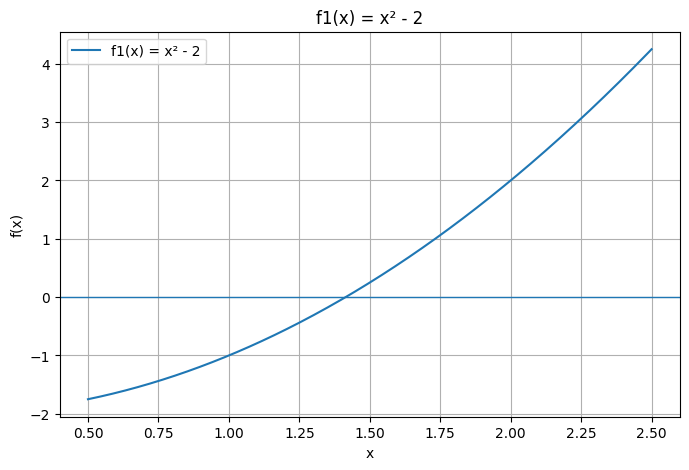

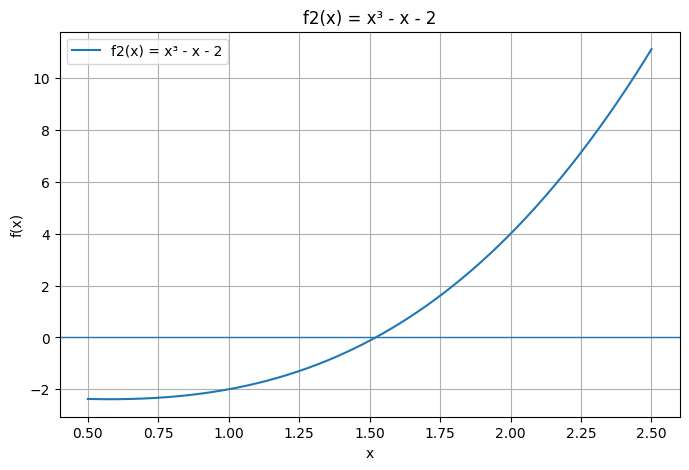

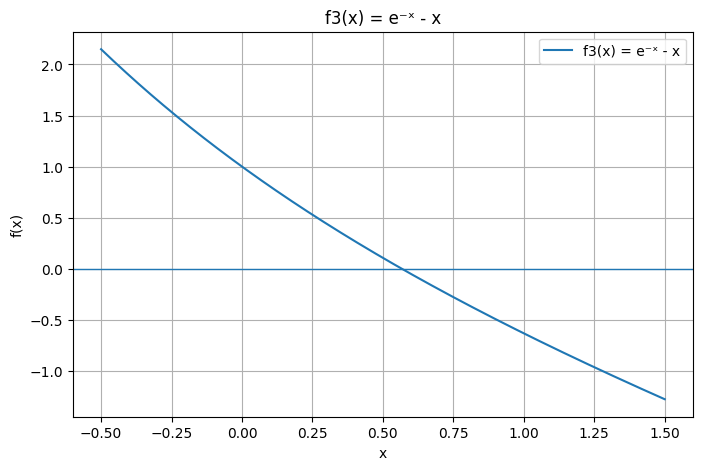

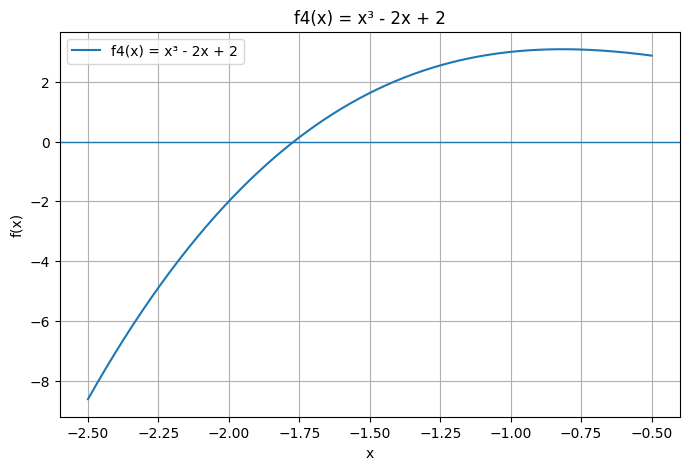

In [28]:
# ==========================================================
# GRÁFICOS DAS FUNÇÕES
# ==========================================================

for nome, dados in funcoes.items():

    f = dados["f"]

    a, b = dados["intervalo"]

    x = np.linspace(
        a - 0.5,
        b + 0.5,
        500
    )

    y = f(x)


    plt.figure(figsize=(8, 5))

    plt.plot(
        x,
        y,
        label=nome
    )

    plt.axhline(
        0,
        linewidth=1
    )

    plt.xlabel("x")
    plt.ylabel("f(x)")

    plt.title(nome)

    plt.grid(True)

    plt.legend()

    plt.show()

Animação Bisseção

In [33]:
def animar_bissecao(nome, dados):

    f = dados["f"]

    a_inicial, b_inicial = dados["intervalo"]

    resultado = bissecao(
        f,
        a_inicial,
        b_inicial
    )

    aproximacoes = resultado["aproximacoes"]


    x = np.linspace(
        a_inicial - 0.5,
        b_inicial + 0.5,
        500
    )


    fig, ax = plt.subplots(
        figsize=(8, 5)
    )


    def atualizar(k):

        ax.clear()

        ax.plot(
            x,
            f(x),
            label=nome
        )

        ax.axhline(
            0,
            linewidth=1
        )


        c = aproximacoes[k]


        # Mostra aproximações anteriores
        ax.scatter(
            aproximacoes[:k+1],
            [
                f(v)
                for v in aproximacoes[:k+1]
            ]
        )


        # Reconstrói intervalo correspondente
        a = a_inicial
        b = b_inicial

        fa = f(a)


        for j in range(k + 1):

            meio = aproximacoes[j]

            fm = f(meio)


            if fa * fm < 0:

                b = meio

            else:

                a = meio
                fa = fm


        # Intervalo atual
        ax.plot(
            [a, b],
            [0, 0],
            linewidth=5,
            alpha=0.4
        )


        ax.set_title(
            f"{nome} - Bisseção\n"
            f"Iteração: {k + 1} | "
            f"x = {c:.8f} | "
            f"|f(x)| = {abs(f(c)):.2e}"
        )

        ax.set_xlabel("x")
        ax.set_ylabel("f(x)")

        ax.grid(True)

        ax.legend()


    animacao = FuncAnimation(
        fig,
        atualizar,
        frames=len(aproximacoes),
        interval=700
    )


    nome_arquivo = (
        nome.replace(" ", "_")
        .replace("(", "")
        .replace(")", "")
        .replace("²", "2")
        .replace("³", "3")
        .replace("⁻", "-")
        .replace("ⁱ", "i")
    )

    filepath = f"bissecao_{nome_arquivo}.gif"

    animacao.save(
        filepath,
        writer=PillowWriter(
            fps=2
        )
    )

    plt.close()

    return filepath

Animação de Newton

In [34]:
def animar_newton(nome, dados):

    f = dados["f"]
    df = dados["df"]

    x0 = dados["x0"]


    resultado = newton(
        f,
        df,
        x0
    )

    aproximacoes = resultado["aproximacoes"]


    x_min = min(aproximacoes) - 0.5
    x_max = max(aproximacoes) + 0.5

    x = np.linspace(
        x_min,
        x_max,
        500
    )


    fig, ax = plt.subplots(
        figsize=(8, 5)
    )


    def atualizar(k):

        ax.clear()


        ax.plot(
            x,
            f(x),
            label=nome
        )

        ax.axhline(
            0,
            linewidth=1
        )


        xk = aproximacoes[k]

        yk = f(xk)

        inclinacao = df(xk)


        # Reta tangente
        tangente = (
            yk
            + inclinacao * (x - xk)
        )


        ax.plot(
            x,
            tangente,
            linestyle="--",
            label="Reta tangente"
        )


        # Aproximações
        valores = aproximacoes[:k+1]


        ax.scatter(
            valores,
            [
                f(v)
                for v in valores
            ]
        )


        ax.scatter(
            [xk],
            [yk]
        )


        ax.set_title(
            f"{nome} - Newton\n"
            f"Iteração: {k} | "
            f"x = {xk:.8f} | "
            f"|f(x)| = {abs(yk):.2e}"
        )

        ax.set_xlabel("x")
        ax.set_ylabel("f(x)")

        ax.grid(True)

        ax.legend()


    animacao = FuncAnimation(
        fig,
        atualizar,
        frames=len(aproximacoes),
        interval=800
    )


    nome_arquivo = (
        nome.replace(" ", "_")
        .replace("(", "")
        .replace(")", "")
        .replace("²", "2")
        .replace("³", "3")
    )

    filepath = f"newton_{nome_arquivo}.gif"

    animacao.save(
        filepath,
        writer=PillowWriter(
            fps=2
        )
    )


    plt.close()

    return filepath

Animação Secante

In [35]:
def animar_secante(nome, dados):

    f = dados["f"]

    x0, x1 = dados["secante"]


    resultado = secante(
        f,
        x0,
        x1
    )

    aproximacoes = resultado["aproximacoes"]


    x_min = min(aproximacoes) - 0.5
    x_max = max(aproximacoes) + 0.5

    x = np.linspace(
        x_min,
        x_max,
        500
    )


    fig, ax = plt.subplots(
        figsize=(8, 5)
    )


    def atualizar(k):

        ax.clear()


        ax.plot(
            x,
            f(x),
            label=nome
        )

        ax.axhline(
            0,
            linewidth=1
        )


        # Os dois pontos da secante
        if k == 0:

            xa = aproximacoes[0]
            xb = aproximacoes[1]

        else:

            xa = aproximacoes[k]
            xb = aproximacoes[k + 1]


        ya = f(xa)
        yb = f(xb)


        # Coeficiente angular
        m = (
            (yb - ya)
            / (xb - xa)
        )


        # Reta secante
        reta = (
            ya
            + m * (x - xa)
        )


        ax.plot(
            x,
            reta,
            linestyle="--",
            label="Reta secante"
        )


        # Pontos
        ax.scatter(
            [xa, xb],
            [ya, yb]
        )


        # Aproximações anteriores
        valores = aproximacoes[
            :k + 2
        ]


        ax.scatter(
            valores,
            [
                f(v)
                for v in valores
            ]
        )


        atual = aproximacoes[
            k + 1
        ]


        ax.set_title(
            f"{nome} - Secante\n"
            f"Iteração: {k + 1} | "
            f"x = {atual:.8f} | "
            f"|f(x)| = {abs(f(atual)):.2e}"
        )

        ax.set_xlabel("x")
        ax.set_ylabel("f(x)")

        ax.grid(True)

        ax.legend()


    animacao = FuncAnimation(
        fig,
        atualizar,
        frames=len(aproximacoes) - 1,
        interval=800
    )


    nome_arquivo = (
        nome.replace(" ", "_")
        .replace("(", "")
        .replace(")", "")
        .replace("²", "2")
        .replace("³", "3")
    )

    filepath = f"secante_{nome_arquivo}.gif"

    animacao.save(
        filepath,
        writer=PillowWriter(
            fps=2
        )
    )


    plt.close()

    return filepath

Gifs

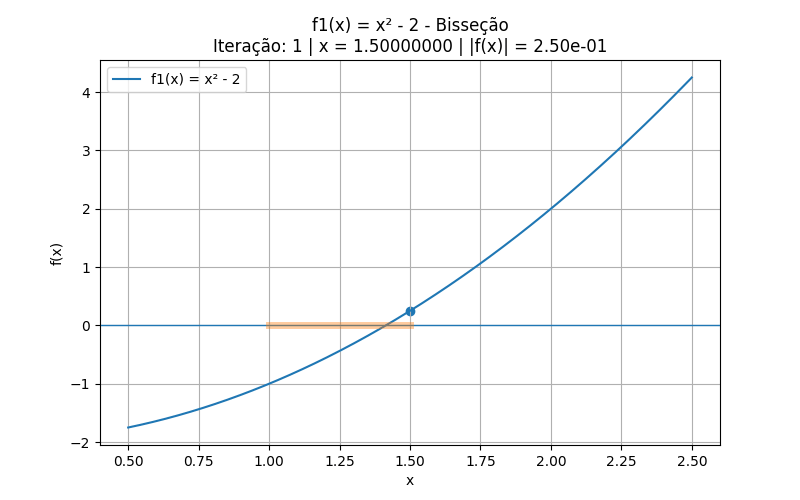

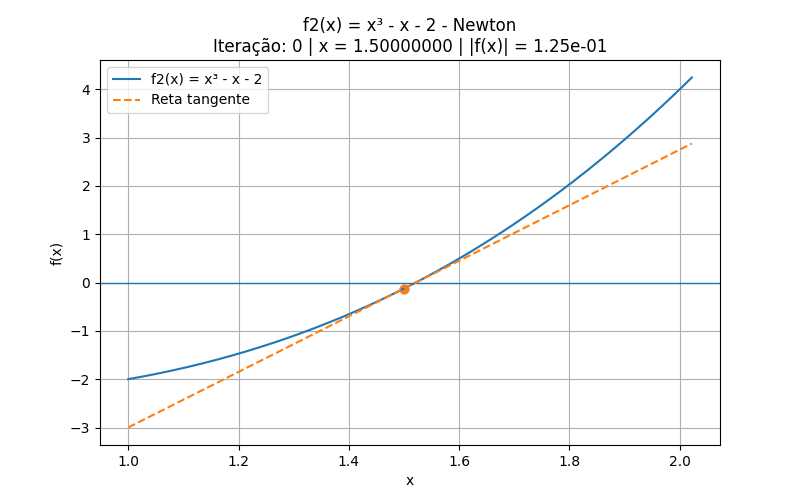

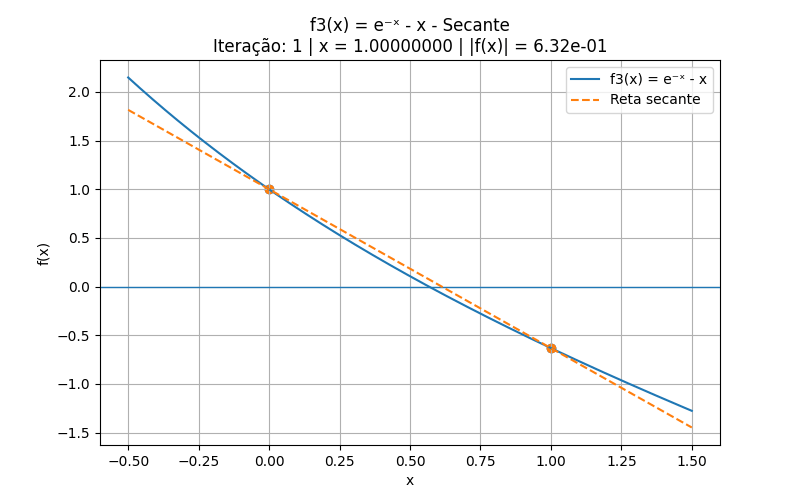

In [36]:
# ==========================================================
# GERAR OS 3 GIFS
# ==========================================================

from IPython.display import Image, display

bissecao_gif_path = animar_bissecao(
    "f1(x) = x² - 2",
    funcoes["f1(x) = x² - 2"]
)
display(Image(filename=bissecao_gif_path))


newton_gif_path = animar_newton(
    "f2(x) = x³ - x - 2",
    funcoes["f2(x) = x³ - x - 2"]
)
display(Image(filename=newton_gif_path))


secante_gif_path = animar_secante(
    "f3(x) = e⁻ˣ - x",
    funcoes["f3(x) = e⁻ˣ - x"]
)
display(Image(filename=secante_gif_path))

In [39]:
from google.colab import files

# Lista dos caminhos dos arquivos GIF gerados
gif_paths = [
    bissecao_gif_path,
    newton_gif_path,
    secante_gif_path
]

for path in gif_paths:
    try:
        files.download(path)
        print(f"O arquivo {path} foi baixado com sucesso.")
    except Exception as e:
        print(f"Não foi possível baixar o arquivo {path}: {e}")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

O arquivo bissecao_f1x_=_x2_-_2.gif foi baixado com sucesso.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

O arquivo newton_f2x_=_x3_-_x_-_2.gif foi baixado com sucesso.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

O arquivo secante_f3x_=_e⁻ˣ_-_x.gif foi baixado com sucesso.
